# Agentic target annotation: GrimAge proteins

Part 2 of the project. GrimAge2 was the clock most associated with schizophrenia in part 1, and it is built from methylation surrogates of seven plasma proteins. This notebook asks an LLM agent to annotate, score and rank those proteins as candidate targets for healthy ageing, then checks the agent's work.

How it works:

1. **Evidence, without an LLM.** Open Targets (tractability, safety, clinical candidates, disease associations), UniProt (function, location) and Europe PMC (publication counts) are queried once per target and cached as JSON in `targets/evidence/`.
2. **The agent.** It reads the cached evidence through tools, scores five dimensions (ageing relevance, mechanism, tractability, safety, clinical precedence) and must cite the facts behind every score. Anything from its own knowledge is listed separately.
3. **The checks.** Cited values are compared with the evidence, the agent is compared with a rule-based baseline, and each target is assessed several times to measure run-to-run stability.

The LLM is set with environment variables (see `.env.example`): Anthropic, OpenAI, or a local OpenAI-compatible server such as Ollama.

In [1]:
# ---- Settings ---------------------------------------------------------------
# Context shown to the agent. Each sentence says exactly what a finding applies to,
# so the agent does not transfer a clock-level result to an individual protein.
_GRIM = ("One of seven plasma proteins whose DNA-methylation surrogates make up the GrimAge clock. "
         "Part 1 of this project: the GrimAge clock as a whole was +4.3 years older in schizophrenia, a difference "
         "that disappeared after adjusting for a methylation smoking score; this protein's own surrogate was not tested. "
         "Surrogates are methylation estimates, not measured protein levels.")
_UP = (" Shirai et al. 2024 (7-cohort meta-analysis): this protein's DNAm surrogate was higher in schizophrenia or "
       "first-episode psychosis in a model adjusted for age, sex and DNAm smoking pack-years.")
_NS = (" Shirai et al. 2024 (7-cohort meta-analysis): this protein's DNAm surrogate did not differ significantly in "
       "the main model adjusted for age, sex and DNAm smoking pack-years.")

# symbol -> context shown to the agent, and literature search terms.
# Curated names avoid ambiguous symbols (e.g. "ADM", "LEP") inflating publication counts.
TARGETS = {
    "ADM":      {"context": _GRIM + _UP, "aliases": ["adrenomedullin", "proadrenomedullin", "MR-proADM"]},
    "B2M":      {"context": _GRIM + _UP, "aliases": ["beta-2-microglobulin", "beta2-microglobulin", "beta 2 microglobulin"]},
    "CST3":     {"context": _GRIM + _UP, "aliases": ["cystatin C", "cystatin-C"]},
    "SERPINE1": {"context": _GRIM + _UP, "aliases": ["plasminogen activator inhibitor-1", "plasminogen activator inhibitor 1", "PAI-1", "SERPINE1"]},
    "GDF15":    {"context": _GRIM + _NS, "aliases": ["GDF15", "GDF-15", "growth differentiation factor 15", "growth differentiation factor-15"]},
    "LEP":      {"context": _GRIM + _NS, "aliases": ["leptin"]},
    "TIMP1":    {"context": _GRIM + _NS, "aliases": ["TIMP-1", "TIMP1", "tissue inhibitor of metalloproteinases-1", "tissue inhibitor of metalloproteinase 1"]},
}
N_RUNS = 3              # assessments per target, to measure stability
REFRESH_EVIDENCE = False  # True re-queries the APIs instead of using the cache

EVIDENCE_DIR = "../targets/evidence"
RESULTS_DIR = "../results"

In [2]:
import sys
from datetime import datetime
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
from clockbench.plots import apply_style
from targetrank import agent, dossier as ds, evaluate, llm, report
from targetrank.rubric import DIMENSIONS, WEIGHTS

apply_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
out = Path(RESULTS_DIR)
out.mkdir(parents=True, exist_ok=True)

try:
    client = llm.from_env()
    print("LLM:", client.describe())
except ValueError as e:
    client = None
    print("No LLM configured:", e, "\nEvidence and baseline sections still run; see .env.example.")

LLM: anthropic:claude-sonnet-5-5 @ https://api.anthropic.com


## 1. Evidence

In [3]:
dossiers = {}
for symbol, t in TARGETS.items():
    dossiers[symbol] = ds.load_or_fetch(symbol, EVIDENCE_DIR, context=t["context"], aliases=t["aliases"],
                                        refresh=REFRESH_EVIDENCE)
print("Evidence retrieved:", sorted({d["retrieved"] for d in dossiers.values()}))

facts = {s: ds.facts(d) for s, d in dossiers.items()}
evidence = pd.DataFrame({s: {
    "protein": f["uniprot.protein_name"],
    "secreted": f["uniprot.secreted"],
    "tractable modalities": ", ".join(m.replace("_", " ") for m in ("small_molecule", "antibody", "protac", "other_modality")
                                      if f[f"tractability.{m}"]) or "none",
    "safety liabilities": f["safety.n_liabilities"],
    "max clinical stage": f["clinical.max_stage_label"],
    "drugs": f["clinical.n_drugs"],
    "age-related disease links": f["associations.n_ageing"],
    "papers": f["literature.any"],
    "ageing share": f["literature.ageing_share"],
    "senescence share": f["literature.senescence_share"],
} for s, f in facts.items()}).T
evidence

Evidence retrieved: ['2026-11-16']


,protein,secreted,tractable modalities,safety liabilities,max clinical stage,drugs,age-related disease links,papers,ageing share,senescence share
ADM,Pro-adrenomedullin,True,"small molecule, antibody, protac",0,PHASE_2_3,1,11,11792,0.1774,0.078
B2M,Beta-2-microglobulin,True,"small molecule, antibody, protac",0,none,0,0,29796,0.1015,0.0501
CST3,Cystatin-C,True,"small molecule, antibody, protac",0,none,0,18,30232,0.2464,0.0553
SERPINE1,Plasminogen activator inhibitor 1,True,"small molecule, antibody, protac",2,PHASE_1,1,7,59619,0.2082,0.1224
GDF15,Growth/differentiation factor 15,True,"antibody, protac",0,none,0,12,16852,0.3471,0.1953
LEP,Leptin,True,antibody,2,none,0,8,143292,0.2313,0.0944
TIMP1,Metalloproteinase inhibitor 1,True,"antibody, protac",2,none,0,10,46110,0.2115,0.1198


In [4]:
# Drugs and the top age-related disease links behind the table, to sanity-check against the Open Targets website
for s, f in facts.items():
    print(f"{s}: drugs = {f['clinical.drugs'] or 'none'}")
    print(f"    age-related links = {f['associations.ageing'][:5] or 'none'}")

ADM: drugs = ['ENIBARCIMAB (PHASE_2_3)']
    age-related links = ['congestive heart failure (0.331)', 'cardiovascular disorder (0.253)', 'skin aging (0.14)', 'essential hypertension (0.132)', 'chronic kidney disease (0.117)']
B2M: drugs = none
    age-related links = none
CST3: drugs = none
    age-related links = ['age-related macular degeneration (0.473)', 'age related macular degeneration 11 (0.463)', 'aging (0.426)', 'chronic kidney disease (0.372)', 'acute coronary syndrome (0.282)']
SERPINE1: drugs = ['ALEPLASININ (PHASE_1)']
    age-related links = ['coronary artery disorder (0.214)', 'ischemic stroke (0.202)', 'type 2 diabetes mellitus (0.124)', 'Alzheimer disease (0.12)', 'chronic obstructive pulmonary disease (0.112)']
GDF15: drugs = none
    age-related links = ['type 2 diabetes mellitus (0.117)', 'coronary artery disorder (0.114)', 'atherosclerosis (0.114)', 'chronic obstructive pulmonary disease (0.113)', 'sarcopenia (0.111)']
LEP: drugs = none
    age-related links = ['ty

## 2. Rule-based baseline

Fixed rules applied to the same facts (see `src/targetrank/rubric.py`). Ageing relevance uses the *share* of each protein's papers that are about ageing or senescence, ranked against the other candidates, plus age-related disease links; raw counts would just reward popular proteins. Deliberately crude: a reference point for the agent, not the answer.

In [5]:
baseline = evaluate.baseline_table(dossiers)
print("Weights:", WEIGHTS)
baseline.sort_values("overall", ascending=False)

Weights: {'ageing_relevance': 0.3, 'mechanism': 0.15, 'tractability': 0.2, 'safety': 0.2, 'clinical_precedence': 0.15}


,ageing_lit_share,ageing_relevance,mechanism,tractability,safety,clinical_precedence,overall
ADM,0.255,4.0,4.0,4.0,4.0,4.0,4.00
SERPINE1,0.331,4.0,4.0,4.0,3.0,2.0,3.50
GDF15,0.542,5.0,4.0,2.0,4.0,1.0,3.45
CST3,0.302,4.0,4.0,3.0,4.0,1.0,3.35
LEP,0.326,4.0,4.0,2.0,3.0,1.0,2.95
TIMP1,0.331,4.0,4.0,2.0,3.0,1.0,2.95
B2M,0.152,1.0,3.0,3.0,4.0,1.0,2.30


## 3. Agent assessments

In [6]:
results = []
if client is None:
    print("Skipped: no LLM configured.")
else:
    run_dir = out / "agent_runs" / datetime.now().strftime("%Y%m%d-%H%M%S")
    stop = False
    for run in range(N_RUNS):
        for symbol in TARGETS:
            r = agent.assess(dossiers[symbol], client, run=run)
            results.append(r)
            status = "ok" if r.assessment else f"FAILED ({r.error})"
            print(f"run {run}  {symbol:<9} {status:<8} turns={r.n_turns}  tools={len(set(r.tools_called))}/7")
            # A rejected request (bad key, model name or parameter) will fail for every target: stop early
            if r.error and any(f"HTTP {c}" in r.error for c in (400, 401, 403, 404)):
                print("Stopping: fix the request error above before re-running.")
                stop = True
                break
        if stop:
            break
    agent.save_results(results, run_dir)
    print("Traces saved to", run_dir)

run 0  ADM       ok       turns=2  tools=7/7
run 0  B2M       ok       turns=2  tools=7/7
run 0  CST3      ok       turns=2  tools=7/7
run 0  SERPINE1  ok       turns=3  tools=7/7
run 0  GDF15     ok       turns=3  tools=7/7
run 0  LEP       ok       turns=2  tools=7/7
run 0  TIMP1     ok       turns=2  tools=7/7
run 1  ADM       ok       turns=2  tools=7/7
run 1  B2M       ok       turns=3  tools=7/7
run 1  CST3      ok       turns=3  tools=7/7
run 1  SERPINE1  ok       turns=2  tools=7/7
run 1  GDF15     ok       turns=2  tools=7/7
run 1  LEP       ok       turns=2  tools=7/7
run 1  TIMP1     ok       turns=2  tools=7/7
run 2  ADM       ok       turns=2  tools=7/7
run 2  B2M       ok       turns=2  tools=7/7
run 2  CST3      ok       turns=2  tools=7/7
run 2  SERPINE1  ok       turns=3  tools=7/7
run 2  GDF15     ok       turns=2  tools=7/7
run 2  LEP       ok       turns=2  tools=7/7
run 2  TIMP1     ok       turns=2  tools=7/7
Traces saved to ../results/agent_runs/20261116-230637


In [7]:
# Did each run finish, use all evidence tools, rely on its own knowledge, and flag conflicts between sources?
summary = evaluate.run_summary(results)
summary.groupby("target")[["completed", "turns", "tool_coverage", "background_claims", "conflicts_flagged"]].mean().round(2)

,completed,turns,tool_coverage,background_claims,conflicts_flagged
target,,,,,
ADM,1.0,2.00,1.0,4.67,2.67
B2M,1.0,2.33,1.0,3.33,3.00
CST3,1.0,2.33,1.0,4.33,2.00
GDF15,1.0,2.33,1.0,3.33,2.67
LEP,1.0,2.00,1.0,4.33,2.00
SERPINE1,1.0,2.67,1.0,3.33,2.00
TIMP1,1.0,2.00,1.0,3.67,3.00


In [15]:
# Runs that needed extra turns or failed: rejected submissions (and why), nudges, repeated tool calls
diag = evaluate.turn_diagnostics(results) if results else pd.DataFrame()
diag[(diag.turns > 3) | ~diag.completed] if not diag.empty else diag

,target,run,turns,completed,rejected_submissions,nudges,repeated_tool_calls,rejection_reasons


## 4. Checks

**Citations.** Every cited fact is looked up in the evidence. *Approximate* means a close paraphrase of a text fact (e.g. a UniProt function sentence), not a verbatim quote. *Mismatch* means the cited value is not in the evidence; *unknown fact* means it cited a fact that does not exist. The last two are hallucinations.

In [18]:
import importlib
importlib.reload(evaluate); importlib.reload(report)

<module 'targetrank.report' from '/work/src/targetrank/report.py'>

In [25]:
citations = evaluate.citation_check(results, dossiers)
print(citations.status.value_counts().to_string() if not citations.empty else "No citations to check.")
citations[citations.status != "match"]   # approximate rows are shown for review

status
match    286


,target,run,dimension,fact_id,cited,actual,status


**Agreement with the baseline** (Spearman correlation across the seven targets, per dimension) and **ranking**, with the range of the agent's overall score across runs.

In [26]:
if results:
    display(evaluate.agreement(results, dossiers).round(2))
    rank = evaluate.ranking(results, dossiers)
    rank.to_csv(out / "target_ranking.csv")
    display(rank)

    dims = evaluate.scores_long(results).groupby(["target", "dimension"]).score.mean().unstack()[list(DIMENSIONS)]
    print("Mean agent score per dimension:")
    display(dims.loc[rank.index].round(1))

,spearman_rho,mean_abs_diff
dimension,,
ageing_relevance,0.00,1.05
mechanism,-0.11,0.86
tractability,0.90,0.14
safety,0.72,0.81
clinical_precedence,1.00,0.14
overall,0.75,0.54


,agent_overall,agent_min,agent_max,baseline_overall,recommendation,agent_rank,baseline_rank
SERPINE1,3.366667,3.30,3.5,3.50,consider,1,2
ADM,3.100000,3.05,3.2,4.00,consider,2,1
CST3,2.850000,2.55,3.0,3.35,deprioritise,3,4
B2M,2.700000,2.70,2.7,2.30,consider,4,7
GDF15,2.700000,2.70,2.7,3.45,consider,4,3
TIMP1,2.500000,2.50,2.5,2.95,deprioritise,6,5
LEP,2.300000,2.30,2.3,2.95,deprioritise,7,5


Mean agent score per dimension:


dimension,ageing_relevance,mechanism,tractability,safety,clinical_precedence
SERPINE1,4.0,4.0,4.0,2.3,2.0
ADM,3.0,2.3,4.0,3.0,3.0
CST3,3.7,2.7,3.0,3.0,1.0
B2M,3.0,3.0,3.0,3.0,1.0
GDF15,3.0,3.0,3.0,3.0,1.0
TIMP1,3.0,3.0,2.0,3.0,1.0
LEP,3.0,3.0,2.0,2.0,1.0


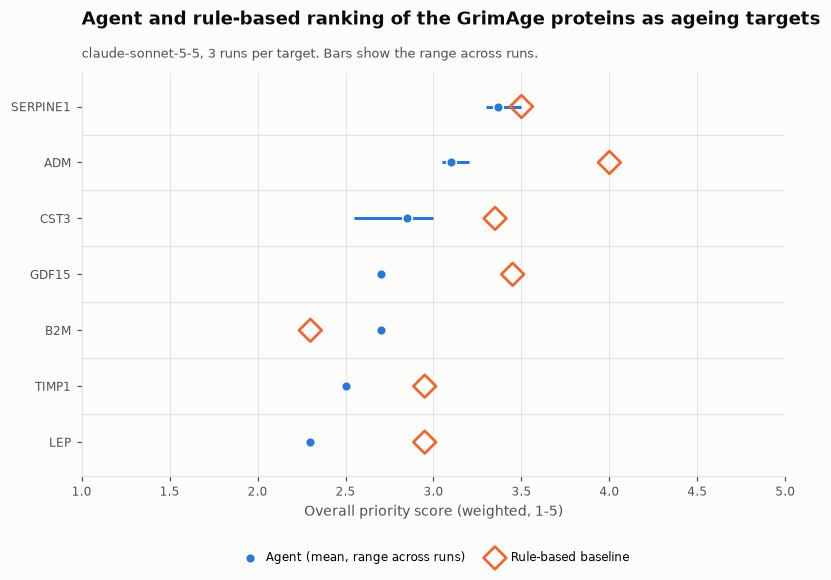

In [27]:
if results:
    fig = report.plot_ranking(
        rank,
        title="Agent and rule-based ranking of the GrimAge proteins as ageing targets",
        subtitle=f"{client.model}, {N_RUNS} runs per target. Bars show the range across runs.",
    )
    fig.savefig(out / "fig5_target_ranking.png")
    plt.show()

## 5. Report

In [28]:
if results:
    path = report.write_report(
        out / "target_report.md", rank, results, citations, model=client.describe(),
        header=f"Candidate targets: the seven GrimAge proteins. Evidence retrieved {sorted({d['retrieved'] for d in dossiers.values()})[-1]}.",
    )
    print("Wrote", path)

Wrote ../results/target_report.md
